# Predictable or Unpredictable: That is the Question!

In [21]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Figure 3. Labeled Predictable XmR Chart

In [22]:
# Depth of cut URL
depth_of_cut_url = r"https://raw.githubusercontent.com/jimlehner/The-Math-Matters/refs/heads/main/the-process-principle/data/magnetic-recievier-depth-of-cut.csv"

# Get the data
doc_df = get_data(depth_of_cut_url)

doc_df["Sample #"] = doc_df["Sample #"].astype(float)

doc_df.head()

,Sample #,Depth of Cut (mils)
0,1.0,160.0
1,2.0,159.7
2,3.0,159.2
3,4.0,159.5
4,5.0,159.6


In [23]:
# Cylinder diameters
depth = doc_df["Depth of Cut (mils)"]
depth_labels = doc_df["Sample #"].astype(int)
# Calculate the moving range
depth_mRs = depth.diff().abs()
depth_mRs.head()

0    NaN
1    0.3
2    0.5
3    0.3
4    0.1
Name: Depth of Cut (mils), dtype: float64

In [24]:
# Calculate process statistics
depth_mean = round(depth.mean(), 2)
depth_ave_mR = round(depth_mRs.mean(), 2)

# Calculate process limits
depth_UPL = round(depth_mean + (2.660 * depth_ave_mR), 2)
depth_LPL = round(depth_mean - (2.660 * depth_ave_mR), 2)
depth_URL = round(3.268 * depth_ave_mR, 2)

print("Mean:", depth_mean)
print("Ave. moving range:", depth_ave_mR)
print("UPL:", depth_UPL)
print("UPL:", depth_LPL)
print("URL:", depth_URL)

Mean: 159.54
Ave. moving range: 0.29
UPL: 160.31
UPL: 158.77
URL: 0.95


In [25]:
# Specify x chart line parameters
depth_xchart_lines = [
    (depth_mean, "-", "black"),
    (depth_UPL, "--", "#d72323"),
    (depth_LPL, "--", "#d72323")
]

# Specify mR chart parameters
depth_mrchart_lines = [
    (depth_ave_mR, "-", "black"),
    (depth_URL, "--", "#d72323"),
]

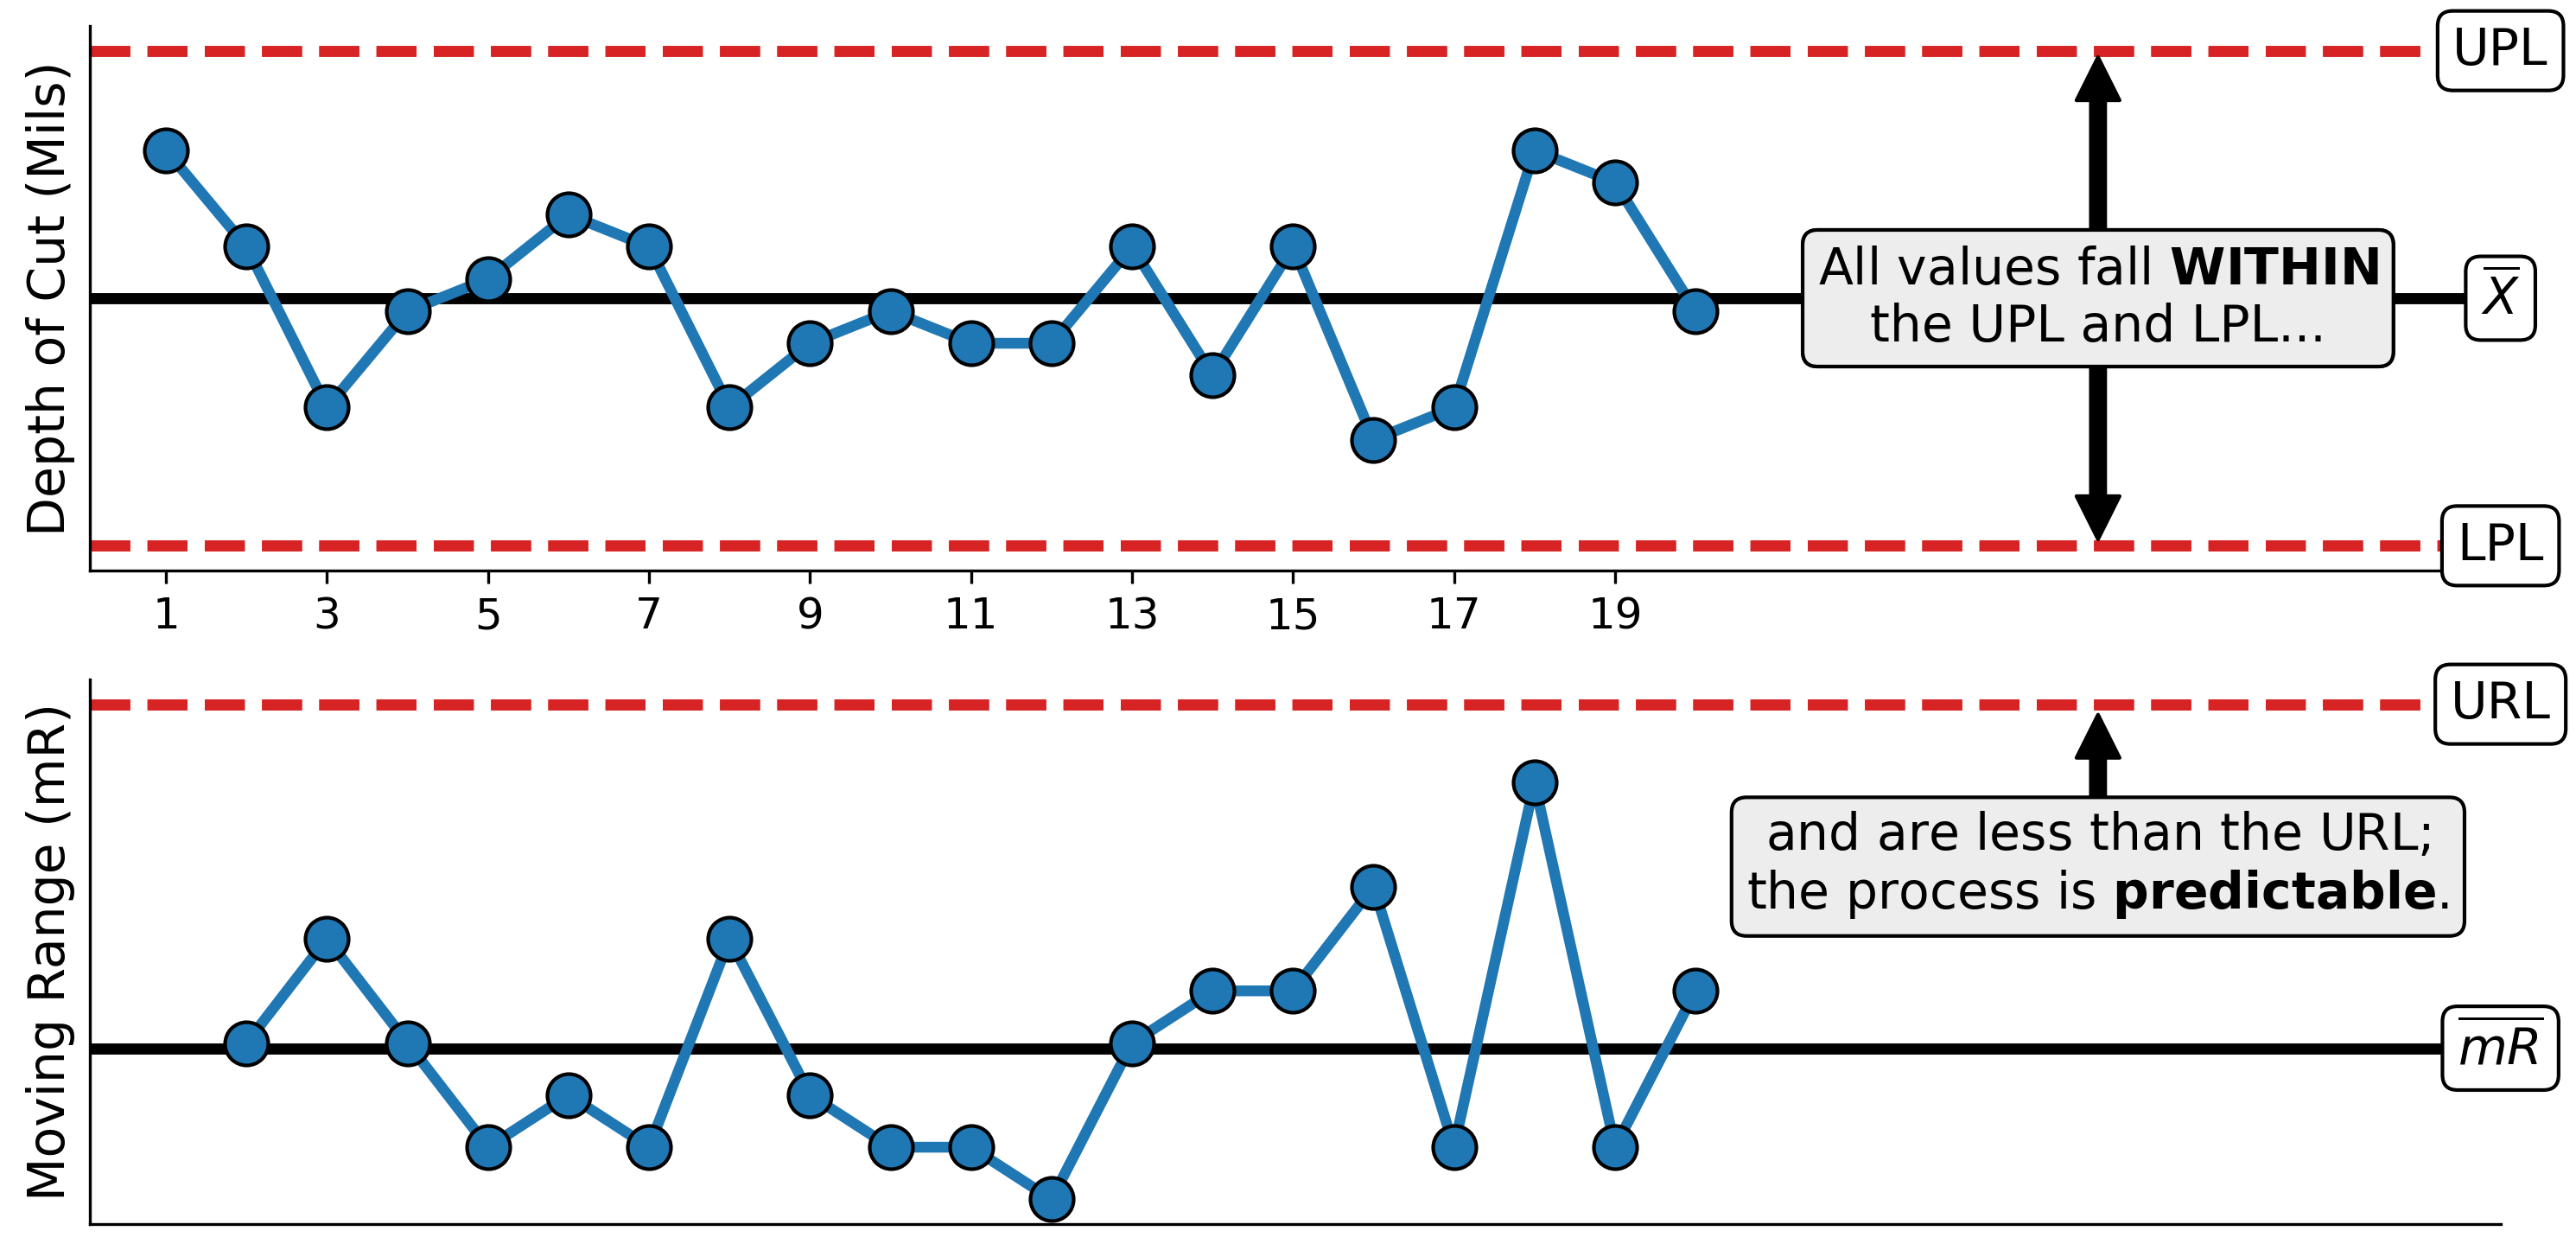

In [26]:
# Create matplotlib figure
fig, axs = plt.subplots(nrows=2, 
                       ncols=1, 
                       figsize=(12,6),
                       dpi=300)

# X chart
axs[0].plot(depth_labels, 
            depth, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify xticks for x chart
tick_positions = np.arange(1, len(depth_labels)+1, 2)
axs[0].set_xticks(tick_positions)
axs[0].set_xticklabels(depth_labels[::2],
                    ha='center', 
                    fontsize=12)

# Extend the x-axis to create room to the right of the data
x_start = axs[0].get_xlim()[0]
x_end = len(depth_labels) + 10

for ax in axs:
    ax.set_xlim(x_start, x_end)

# Plot X chart limits and center line
for value, line_type, color in depth_xchart_lines:
    axs[0].axhline(
        value,
        ls=line_type,
        linewidth=3,
        c=color
    )

# Plot mR chart limits and center line
for value, line_type, color in depth_mrchart_lines:
    axs[1].axhline(
        value,
        ls=line_type,
        linewidth=3,
        c=color
    )

for value, line_type, color in depth_xchart_lines:
    axs[0].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)

# mR chart
axs[1].plot(depth_labels,
            depth_mRs, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

for value, line_type, color in depth_mrchart_lines:
    axs[1].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)
    
# Offset moving range by one relative to the indivual values
for xi, yi in zip(depth_labels, depth_mRs):
    if np.isnan(yi):
        axs[1].plot(xi, 
                    0, 
                    marker='x', 
                    color='white', 
                    markersize=0) 

# Get x limit of subplots
xlim = axs[0].get_xlim()[1]
mrlim = axs[1].get_xlim()[1]

# Define annotation values
annotations = [
    ("UPL", xlim, depth_UPL, axs[0]),
    ("LPL", xlim, depth_LPL, axs[0]),
    ("$\overline{{X}}$", xlim, depth_mean, axs[0]),
    ("URL", xlim, depth_URL, axs[1]),
    ("$\overline{{mR}}$", xlim, depth_ave_mR, axs[1]),
]
        
# Add central line and process limit annotations
for label, x_pos, y_pos, axis in annotations:
    axis.annotate(label,
                 xy=(x_pos, y_pos), 
                 ha="center", 
                 va="center", 
                 fontsize=14, 
                 bbox=dict(
                     facecolor='white', 
                     boxstyle='round')
                )
        
        
# Add y-axis titles
axs[0].set_ylabel("Depth of Cut (Mils)", 
                  fontsize=14)
axs[1].set_ylabel("Moving Range (mR)", 
                  fontsize=14)

# Remove x and y ticks
for ax in axs:
    ax.set_yticks([])

# Remove xticks from mR chart
axs[1].set_xticks([])

# Annotation text and formatting
annotation_text_xchart = (
    r"All values fall $\mathbf{WITHIN}$" "\n"
    "the UPL and LPL..."
)

annotation_text_mrchart = (
    r"and are $\text{less}\ \text{than}$ the URL;" "\n"
    r"the process is $\mathbf{predictable}$."
)

# Add annotations pointing to both process limits
for limit in [depth_UPL - 0.02, depth_LPL + 0.02]:
    axs[0].annotate(
        annotation_text_xchart,
        xy=(25, limit),
        xytext=(25, depth_mean),
        ha='center',
        va='center',
        fontsize=14,
        bbox=dict(facecolor='#EDEDED', boxstyle='round'),
        arrowprops=dict(
            color='black',
            linewidth=1
        )
    )
    
# Add annotations pointing to both process limits
for limit in [depth_URL - 0.02]:
    axs[1].annotate(
        annotation_text_mrchart,
        xy=(25, limit),
        xytext=(25, depth_ave_mR+0.35),
        ha='center',
        va='center',
        fontsize=14,
        bbox=dict(facecolor='#EDEDED', boxstyle='round'),
        arrowprops=dict(
            color='black',
            linewidth=1
        )
    )
    
# Despine
sns.despine()
    
plt.show()

# Figure 4. Labeled Unpredictable XmR Chart

In [27]:
# Depth of cut URL
fill_weight_url = r"https://raw.githubusercontent.com/jimlehner/The-Math-Matters/refs/heads/main/the-process-principle/data/fill-weights.csv"

# Get the data
fill_df = get_data(fill_weight_url)

fill_df["Sample #"] = fill_df["Sample"].astype(float)

fill_df.head()

,Sample,Fill Weight (g),Sample #
0,1,905,1.0
1,2,915,2.0
2,3,930,3.0
3,4,890,4.0
4,5,940,5.0


In [28]:
# Cylinder diameters
fill = fill_df["Fill Weight (g)"]
fill_labels = fill_df["Sample"].astype(int)
# Calculate the moving range
fill_mRs = fill.diff().abs()
fill_mRs.head()

0     NaN
1    10.0
2    15.0
3    40.0
4    50.0
Name: Fill Weight (g), dtype: float64

In [29]:
# Calculate process statistics
fill_mean = round(fill.mean(), 2)
fill_ave_mR = round(fill_mRs.mean(), 2)

# Calculate process limits
fill_UPL = round(fill_mean + (2.660 * fill_ave_mR), 2)
fill_LPL = round(fill_mean - (2.660 * fill_ave_mR), 2)
fill_URL = round(3.268 * fill_ave_mR, 2)

print("Mean:", fill_mean)
print("Ave. moving range:", fill_ave_mR)
print("UPL:", fill_UPL)
print("UPL:", fill_LPL)
print("URL:", fill_URL)

Mean: 955.89
Ave. moving range: 31.67
UPL: 1040.13
UPL: 871.65
URL: 103.5


In [30]:
# Specify x chart line parameters
fill_xchart_lines = [
    (fill_mean, "-", "black"),
    (fill_UPL, "--", "#d72323"),
    (fill_LPL, "--", "#d72323")
]

# Specify mR chart parameters
fill_mrchart_lines = [
    (fill_ave_mR, "-", "black"),
    (fill_URL, "--", "#d72323"),
]

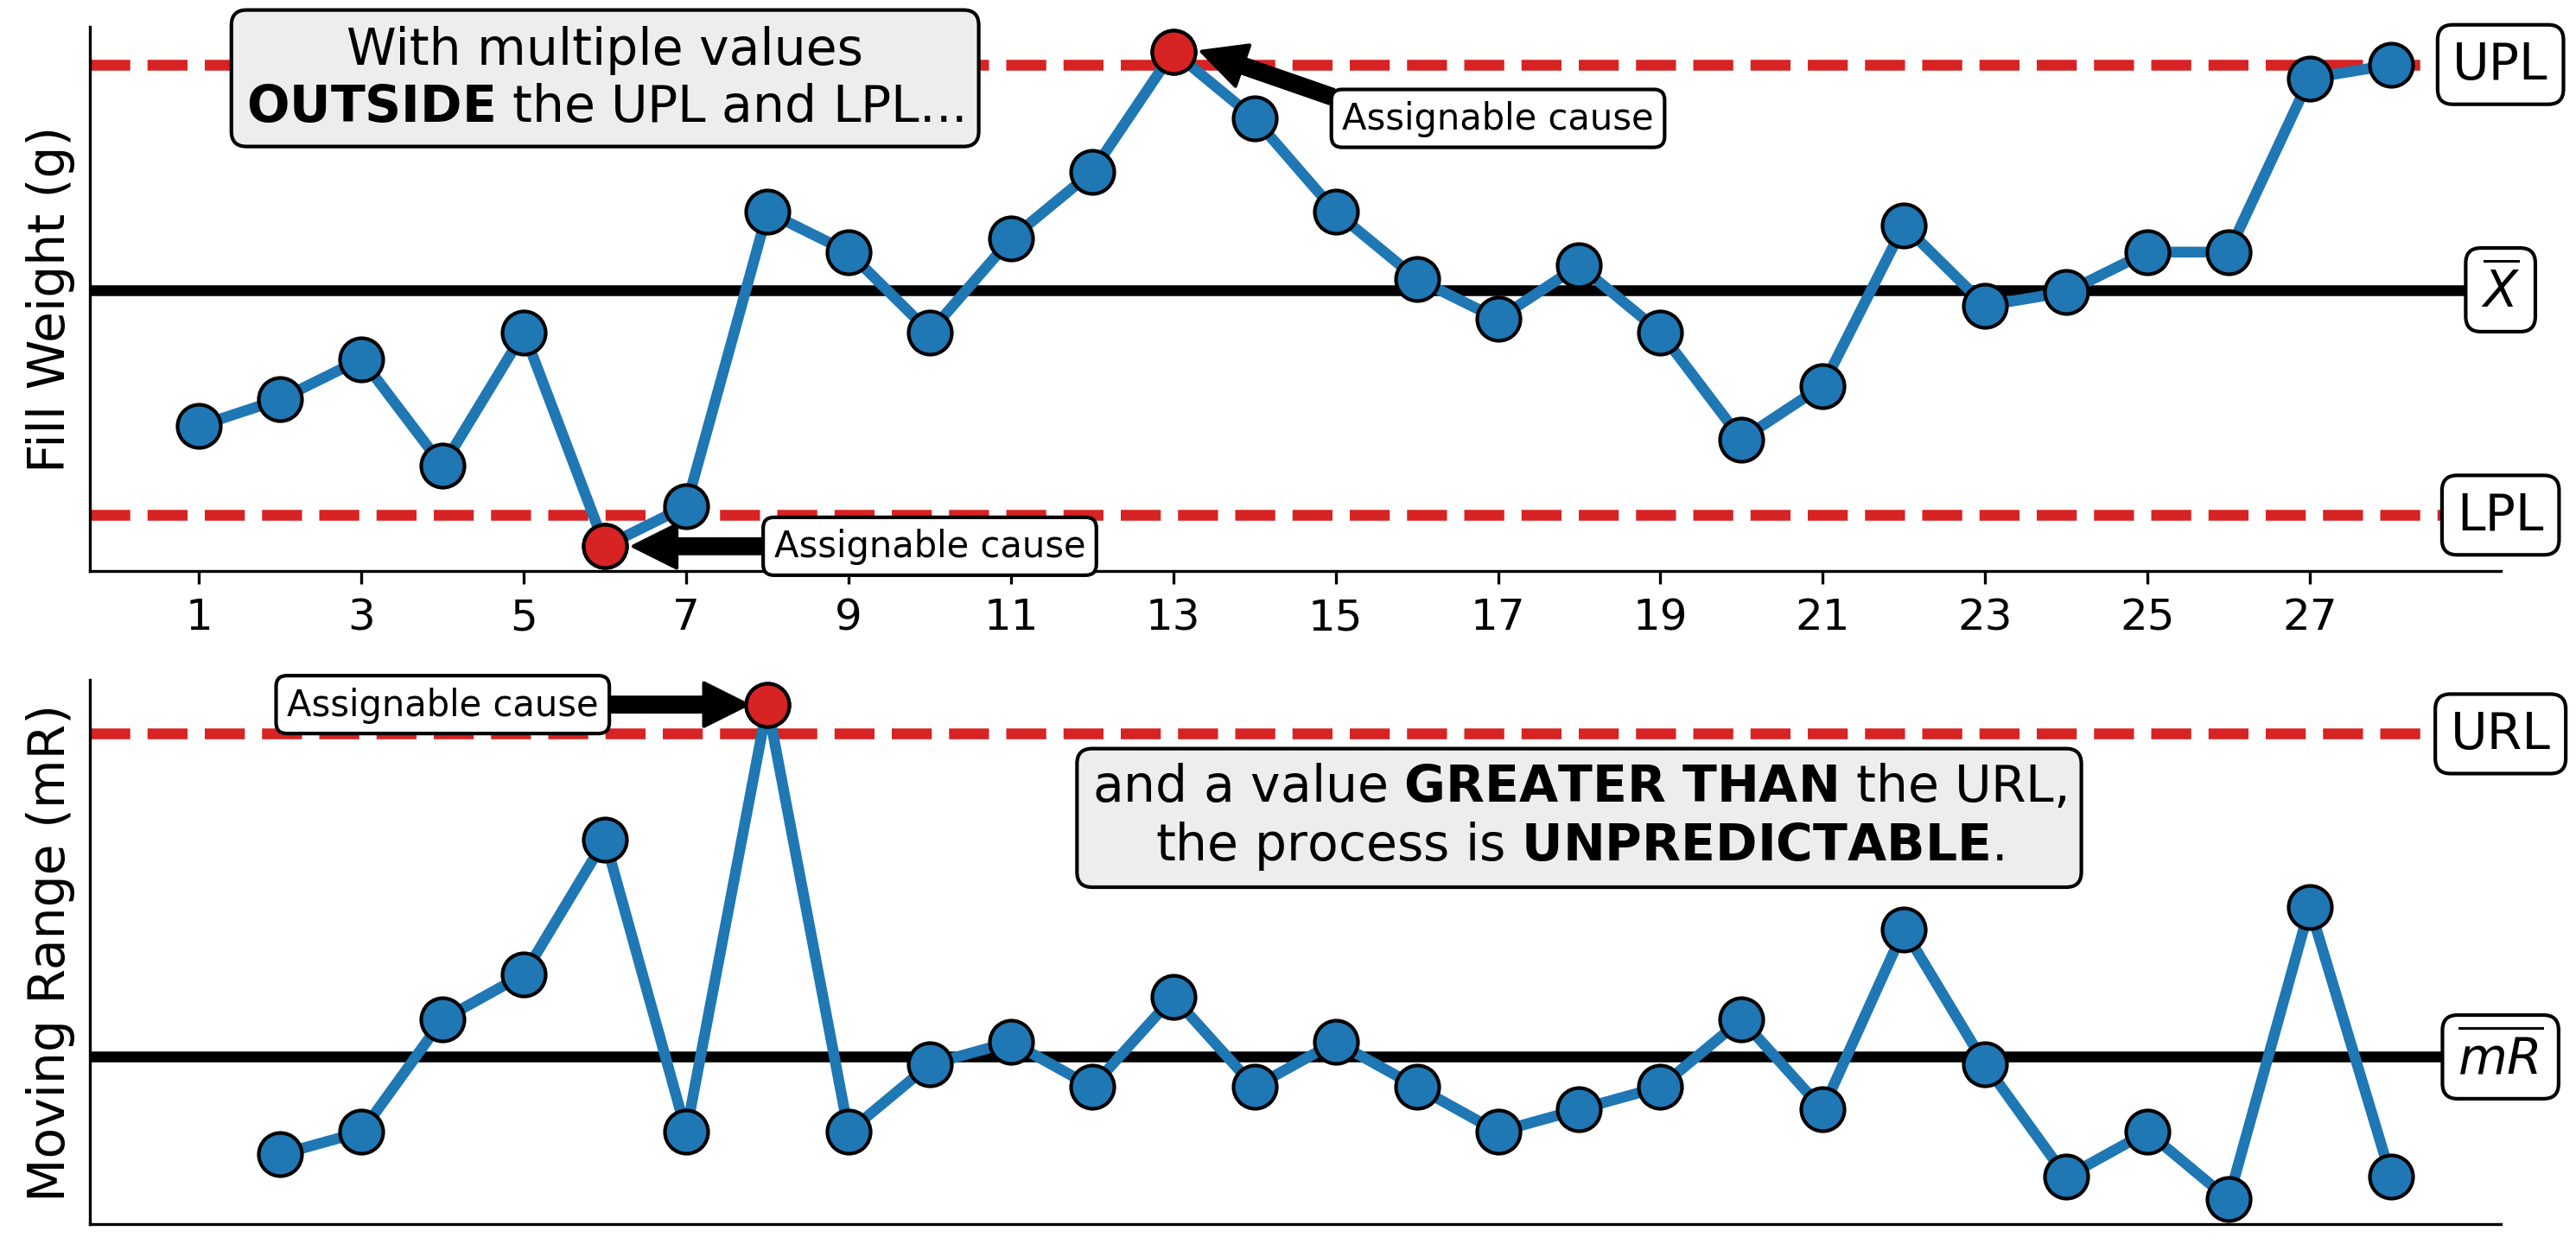

In [31]:
# Create matplotlib figure
fig, axs = plt.subplots(nrows=2, 
                       ncols=1, 
                       figsize=(12,6),
                       dpi=300)

# --- X chart ---
axs[0].plot(fill_labels, 
            fill, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify assignable cause conditions
below_fill_LPL = fill < fill_LPL
above_fill_UPL = fill > fill_UPL

# Highlight values less than LPL
axs[0].plot(fill_labels[below_fill_LPL],
            fill[below_fill_LPL],
            marker="o",
            markersize=12,
            markeredgecolor="black",
            markerfacecolor="#d72323",
            linestyle="none",
            zorder=5
           )

# Highlight values greater than the UPL
axs[0].plot(fill_labels[above_fill_UPL],
            fill[above_fill_UPL],
            marker="o",
            markersize=12,
            markeredgecolor="black",
            markerfacecolor="#d72323",
            linestyle="none",
            zorder=5
           )

# Specify xticks for x chart
tick_positions = np.arange(1, len(fill_labels)+1, 1)
axs[0].set_xticks(tick_positions[::2])
axs[0].set_xticklabels(fill_labels.iloc[::2], 
                    ha='center', 
                    fontsize=12)

for value, line_type, color in fill_xchart_lines:
    axs[0].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)

# --- mR chart ---
axs[1].plot(fill_labels,
            fill_mRs, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

for value, line_type, color in fill_mrchart_lines:
    axs[1].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)
    
# Offset moving range by one relative to the indivual values
for xi, yi in zip(fill_labels, depth_mRs):
    if np.isnan(yi):
        axs[1].plot(xi, 
                    0, 
                    marker='x', 
                    color='white', 
                    markersize=0) 

# Specify assignable cause condition
above_fill_URL = fill_mRs > fill_URL

# Highlight mR assignable causes
axs[1].plot(fill_labels[above_fill_URL],
            fill_mRs[above_fill_URL],
            marker="o",
            markersize=12,
            markeredgecolor="black",
            markerfacecolor="#d72323",
            linestyle="none",
            zorder=5
           )        

# Get x limit of subplots
xlim = axs[0].get_xlim()[1]
mrlim = axs[1].get_xlim()[1]

# Define annotation values
annotations = [
    ("UPL", xlim, fill_UPL, axs[0]),
    ("LPL", xlim, fill_LPL, axs[0]),
    ("$\overline{{X}}$", xlim, fill_mean, axs[0]),
    ("URL", xlim, fill_URL, axs[1]),
    ("$\overline{{mR}}$", xlim, fill_ave_mR, axs[1]),
]
        
# Add central line and process limit annotations
for label, x_pos, y_pos, axis in annotations:
    axis.annotate(label,
                 xy=(x_pos, y_pos), 
                 ha="center", 
                 va="center", 
                 fontsize=14, 
                 bbox=dict(
                     facecolor='white', 
                     boxstyle='round')
                )
        
        
# Add y-axis titles
axs[0].set_ylabel("Fill Weight (g)", 
                  fontsize=14)
axs[1].set_ylabel("Moving Range (mR)", 
                  fontsize=14)

# Remove x and y ticks
for ax in axs:
    ax.set_yticks([])

# Remove xticks from mR chart
axs[1].set_xticks([])

# Reusable annotation styles
arrow_style = dict(
    color='black',
    linewidth=1
)

cause_box = dict(facecolor='white', boxstyle='round')
explanation_box = dict(facecolor='#EDEDED', boxstyle='round')

# Assignable cause annotations: (axis, arrow point, text position)
assignable_causes = [
    (axs[0], (13.35, 1045), (17, 1020)),
    (axs[0], (6.35, 860), (10, 860)),
    (axs[1], (7.75, 110), (4, 110))
]

for ax, xy, xytext in assignable_causes:
    ax.annotate(
        "Assignable cause",
        xy=xy,
        xytext=xytext,
        ha='center',
        va='center',
        bbox=cause_box,
        arrowprops=arrow_style
    )

# X chart explanation
axs[0].annotate(
    "With multiple values\n"
    r"$\mathbf{OUTSIDE}$ the UPL and LPL...",
    xy=(6, 1035),
    ha='center',
    va='center',
    fontsize=14,
    bbox=explanation_box
)

# Moving range chart explanation
axs[1].annotate(
    r"and a value $\mathbf{GREATER\ THAN}$ the URL," "\n"
    r"the process is $\mathbf{UNPREDICTABLE}$.",
    xy=(18, 85),
    ha='center',
    va='center',
    fontsize=14,
    bbox=explanation_box
)

# Despine
sns.despine()
    
plt.show()

# Figure 6. XmR chart of 1/8 inch diameter pin measurements

In [32]:
dataset_url = r'https://raw.githubusercontent.com/jimlehner/The-Math-Matters/refs/heads/main/predictable-or-unpredictable-that-is-the-question/data/machine_screw_manufacturing.csv'

# Get data function
def get_data(dataset_url) -> pd.DataFrame:
    return pd.read_csv(dataset_url)

# Get the data
df = get_data(dataset_url)

df.index = range(1, len(df) + 1)

df.reset_index(names='Sample', inplace=True)

df['Sample'] = df['Sample'].astype(str)

df.head()

,Sample,MACHINE,DAY,"TIME (1 = AM, 2 = PM)",SAMPLE,DIAMETER (in)
0,1,1,1,1,1,0.1247
1,2,1,1,1,2,0.1264
2,3,1,1,1,3,0.1252
3,4,1,1,1,4,0.1253
4,5,1,1,1,5,0.1263


In [33]:
# Cylinder diameters
diameters = df["DIAMETER (in)"]
labels = df["Sample"].astype(int)
# Calculate the moving range
mRs = diameters.diff().abs()
mRs.head()

0       NaN
1    0.0017
2    0.0012
3    0.0001
4    0.0010
Name: DIAMETER (in), dtype: float64

In [34]:
# Calculate process statistics
mean = round(diameters.mean(), 4)
ave_mR = round(mRs.mean(), 4)

# Calculate process limits
UPL = round(mean + (2.660 * ave_mR), 4)
LPL = round(mean - (2.660 * ave_mR), 4)
URL = round(3.268 * ave_mR, 4)

print("Mean:", mean)
print("Ave. moving range:", ave_mR)
print("UPL:", UPL)
print("UPL:", LPL)
print("URL:", URL)

Mean: 0.1249
Ave. moving range: 0.0013
UPL: 0.1284
UPL: 0.1214
URL: 0.0042


In [35]:
# Specify x chart line parameters
xchart_lines = [
    (mean, "-", "black"),
    (UPL, "--", "#d72323"),
    (LPL, "--", "#d72323")
]

# Specify mR chart parameters
mrchart_lines = [
    (ave_mR, "-", "black"),
    (URL, "--", "#d72323"),
]

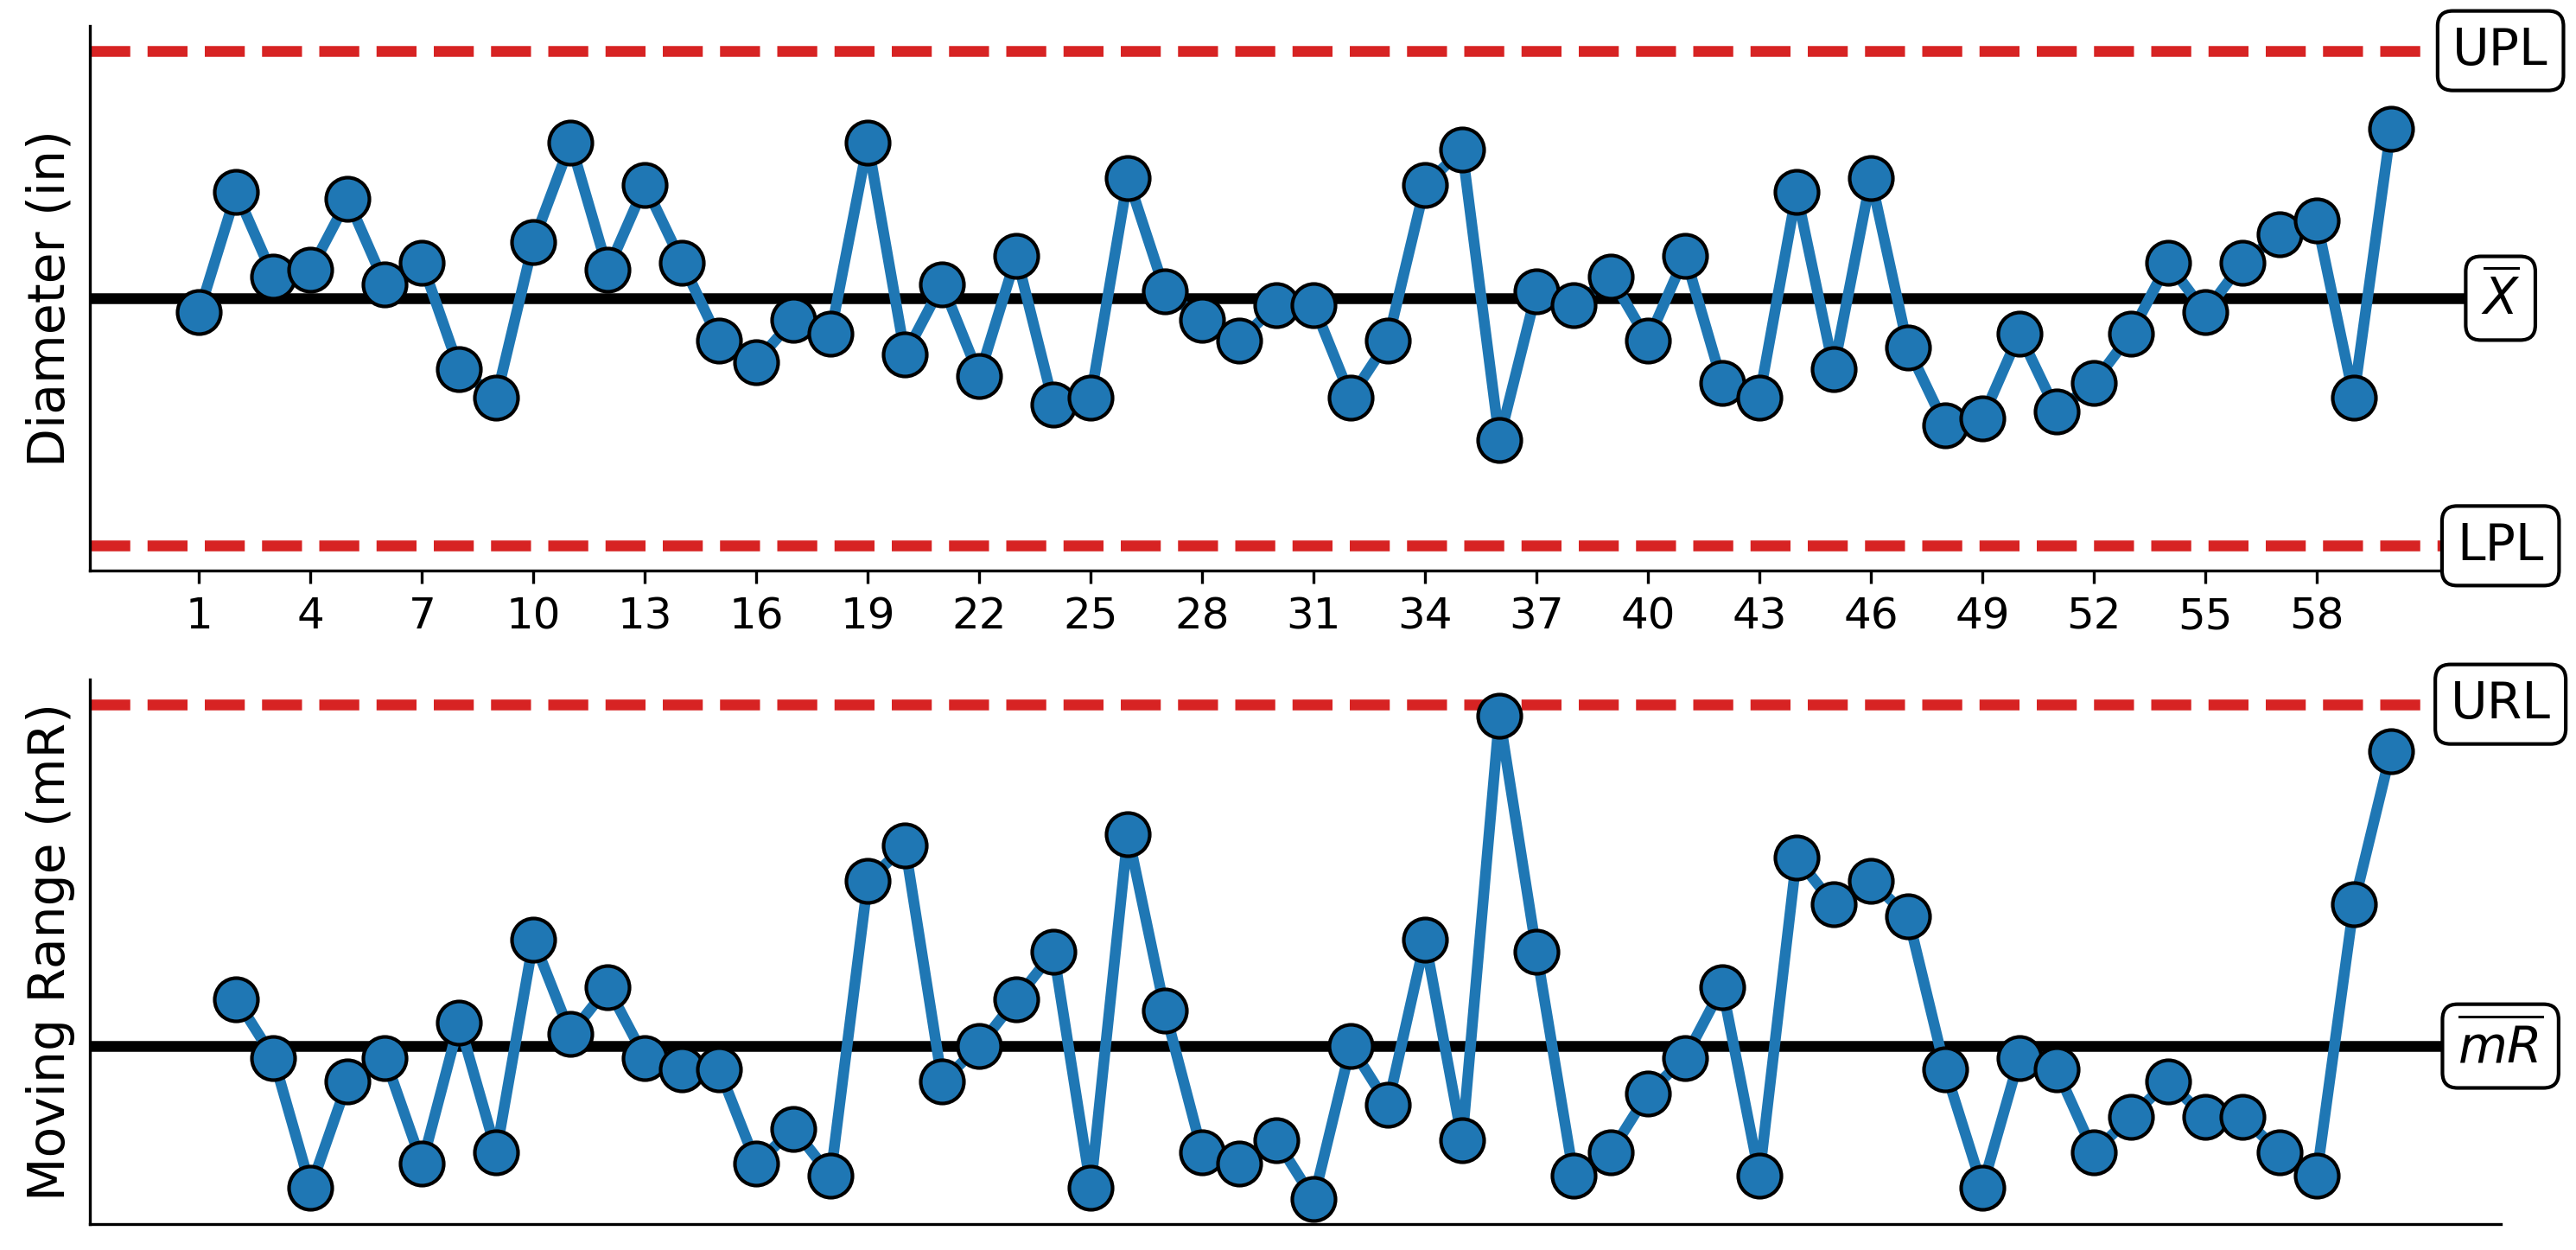

In [36]:
# Create matplotlib figure
fig, axs = plt.subplots(nrows=2, 
                       ncols=1, 
                       figsize=(12,6),
                       dpi=300)

# X chart
axs[0].plot(labels, 
            diameters, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify xticks for x chart
tick_positions = np.arange(1, len(labels)+1, 1)
axs[0].set_xticks(tick_positions)
axs[0].set_xticklabels(labels, 
                    ha='center', 
                    fontsize=12)

for value, line_type, color in xchart_lines:
    axs[0].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)

# mR chart
axs[1].plot(labels,
            mRs, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

for value, line_type, color in mrchart_lines:
    axs[1].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)
    
# Offset moving range by one relative to the indivual values
for xi, yi in zip(labels, mRs):
    if np.isnan(yi):
        axs[1].plot(xi, 
                    0, 
                    marker='x', 
                    color='white', 
                    markersize=0) 

# Get x limit of subplots
xlim = axs[0].get_xlim()[1]
mrlim = axs[1].get_xlim()[1]

# Define annotation values
annotations = [
    ("UPL", xlim, UPL, axs[0]),
    ("LPL", xlim, LPL, axs[0]),
    ("$\overline{{X}}$", xlim, mean, axs[0]),
    ("URL", xlim, URL, axs[1]),
    ("$\overline{{mR}}$", xlim, ave_mR, axs[1]),
]
        
# Add central line and process limit annotations
for label, x_pos, y_pos, axis in annotations:
    axis.annotate(label,
                 xy=(x_pos, y_pos), 
                 ha="center", 
                 va="center", 
                 fontsize=14, 
                 bbox=dict(
                     facecolor='white', 
                     boxstyle='round')
                )
        
        
# Add y-axis titles
axs[0].set_ylabel("Diameter (in)", 
                  fontsize=14)
axs[1].set_ylabel("Moving Range (mR)", 
                  fontsize=14)

# Remove x and y ticks
for ax in axs:
    ax.set_yticks([])

# Remove xticks from mR chart
axs[1].set_xticks([])

axs[0].locator_params(axis="x", nbins=20)
    
# Despine
sns.despine()
    
plt.show()